## 1. Import Libraries

In [2]:
import os

print(os.getcwd())
print(os.listdir())

C:\flight_price prediction_AWS_sagemaker\notebook
['.ipynb_checkpoints', 'data_cleaning.ipynb', 'eda.ipynb', 'eda_helper_functions.py', '__pycache__']


In [1]:
import numpy as np

import pandas as pd

import seaborn as sns

import matplotlib.pyplot as plt

import eda_helper_functions

from sklearn.ensemble import IsolationForest

## 2. Read the Training Data

In [5]:
file_path = r"C:\flight_price prediction_AWS_sagemaker\Dataset\train.csv"

train = pd.read_csv(file_path)
train

,airline,date_of_journey,source,destination,dep_time,arrival_time,duration,total_stops,additional_info,price
0,Indigo,2019-04-27,Delhi,Cochin,16:00:00,21:00:00,300,1.0,No Info,6937
1,Vistara,2019-04-01,Kolkata,Banglore,07:10:00,23:25:00,975,1.0,No Info,7927
2,Jet Airways,2019-05-27,Delhi,Cochin,14:00:00,19:00:00,300,1.0,In-flight meal not included,12898
3,Jet Airways,2019-06-24,Delhi,Cochin,20:55:00,19:00:00,1325,1.0,In-flight meal not included,10262
4,Jet Airways,2019-05-18,Delhi,Cochin,14:00:00,19:00:00,300,1.0,In-flight meal not included,12373
...,...,...,...,...,...,...,...,...,...,...
635,Air India,2019-06-01,Delhi,Cochin,14:25:00,19:15:00,1730,2.0,No Info,13591
636,Indigo,2019-04-27,Banglore,Delhi,04:00:00,06:50:00,170,0.0,No Info,4423
637,Multiple Carriers,2019-06-06,Delhi,Cochin,11:25:00,19:00:00,455,1.0,No Info,10877
638,Indigo,2019-04-12,Banglore,Delhi,10:10:00,13:00:00,170,0.0,No Info,4591


### 2.1 Fixing Data Types

In [6]:
train.dtypes

airline                str
date_of_journey        str
source                 str
destination            str
dep_time               str
arrival_time           str
duration             int64
total_stops        float64
additional_info        str
price                int64
dtype: object

In [7]:
train = train.assign(**{
	col: pd.to_datetime(train.loc[:, col], dayfirst=True, format="mixed")
	for col in ["date_of_journey", "dep_time", "arrival_time"]
})

train.dtypes

airline                       str
date_of_journey    datetime64[us]
source                        str
destination                   str
dep_time           datetime64[us]
arrival_time       datetime64[us]
duration                    int64
total_stops               float64
additional_info               str
price                       int64
dtype: object

In [8]:
train

,airline,date_of_journey,source,destination,dep_time,arrival_time,duration,total_stops,additional_info,price
0,Indigo,2019-04-27,Delhi,Cochin,2026-10-11 16:00:00,2026-10-11 21:00:00,300,1.0,No Info,6937
1,Vistara,2019-01-04,Kolkata,Banglore,2026-10-11 07:10:00,2026-10-11 23:25:00,975,1.0,No Info,7927
2,Jet Airways,2019-05-27,Delhi,Cochin,2026-10-11 14:00:00,2026-10-11 19:00:00,300,1.0,In-flight meal not included,12898
3,Jet Airways,2019-06-24,Delhi,Cochin,2026-10-11 20:55:00,2026-10-11 19:00:00,1325,1.0,In-flight meal not included,10262
4,Jet Airways,2019-05-18,Delhi,Cochin,2026-10-11 14:00:00,2026-10-11 19:00:00,300,1.0,In-flight meal not included,12373
...,...,...,...,...,...,...,...,...,...,...
635,Air India,2019-01-06,Delhi,Cochin,2026-10-11 14:25:00,2026-10-11 19:15:00,1730,2.0,No Info,13591
636,Indigo,2019-04-27,Banglore,Delhi,2026-10-11 04:00:00,2026-10-11 06:50:00,170,0.0,No Info,4423
637,Multiple Carriers,2019-06-06,Delhi,Cochin,2026-10-11 11:25:00,2026-10-11 19:00:00,455,1.0,No Info,10877
638,Indigo,2019-12-04,Banglore,Delhi,2026-10-11 10:10:00,2026-10-11 13:00:00,170,0.0,No Info,4591


## 3. High-level Summary of Data

In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 640 entries, 0 to 639
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   airline          640 non-null    object        
 1   date_of_journey  640 non-null    datetime64[ns]
 2   source           640 non-null    object        
 3   destination      640 non-null    object        
 4   dep_time         640 non-null    datetime64[ns]
 5   arrival_time     640 non-null    datetime64[ns]
 6   duration         640 non-null    int64         
 7   total_stops      640 non-null    float64       
 8   additional_info  640 non-null    object        
 9   price            640 non-null    int64         
dtypes: datetime64[ns](3), float64(1), int64(2), object(4)
memory usage: 50.1+ KB


In [12]:
train.describe(include="number")

,duration,total_stops,price
count,640.000000,640.000000,640.000000
mean,660.054688,0.839063,9215.284375
std,517.059555,0.645707,4402.127355
min,80.000000,0.000000,1759.000000
25%,178.750000,0.000000,5554.000000
50%,522.500000,1.000000,8366.000000
75%,943.750000,1.000000,12864.250000
max,2315.000000,3.000000,34503.000000


In [14]:
(
	train
	.assign(total_stops=train["total_stops"].astype(object))
	.describe(include=["str"])
)

,airline,source,destination,additional_info
count,640,640,640,640
unique,8,5,6,3
top,Jet Airways,Delhi,Cochin,No Info
freq,243,294,294,483


## 4. High-level analysis of Missing Values

In [15]:
eda_helper_functions.missing_info(train)

,count,percentage
variable,,


## 5. High-level analysis of Outliers

In [16]:
forest = IsolationForest(n_estimators=10, random_state=42)

In [17]:
(
	train
	.assign(outlier=forest.fit_predict(
		train
		.drop(columns="price")
		.select_dtypes(include="number")
	))
	.query("outlier == -1")
	# .duration
	# .describe()
)

,airline,date_of_journey,source,destination,dep_time,arrival_time,duration,total_stops,additional_info,price,outlier
3,Jet Airways,2019-06-24,Delhi,Cochin,2026-10-11 20:55:00,2026-10-11 19:00:00,1325,1.0,In-flight meal not included,10262,-1
5,Vistara,2019-01-06,Delhi,Cochin,2026-10-11 06:00:00,2026-10-11 09:10:00,190,0.0,No Info,6741,-1
9,Jet Airways,2019-09-06,Delhi,Cochin,2026-10-11 09:25:00,2026-10-11 12:35:00,1630,2.0,No Info,13882,-1
10,Jet Airways,2019-06-27,Delhi,Cochin,2026-10-11 23:05:00,2026-10-11 04:25:00,1760,2.0,In-flight meal not included,11150,-1
13,Indigo,2019-12-04,Kolkata,Banglore,2026-10-11 15:15:00,2026-10-11 17:45:00,150,0.0,No Info,4174,-1
...,...,...,...,...,...,...,...,...,...,...,...
629,Indigo,2019-06-21,Mumbai,Hyderabad,2026-10-11 09:10:00,2026-10-11 10:40:00,90,0.0,No Info,5755,-1
631,Spicejet,2019-06-18,Banglore,Delhi,2026-10-11 05:55:00,2026-10-11 08:35:00,160,0.0,No Info,3625,-1
633,Jet Airways,2019-06-27,Delhi,Cochin,2026-10-11 05:30:00,2026-10-11 12:35:00,425,2.0,No Info,14441,-1
635,Air India,2019-01-06,Delhi,Cochin,2026-10-11 14:25:00,2026-10-11 19:15:00,1730,2.0,No Info,13591,-1


## 6. Pair Plots

In [21]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 640 entries, 0 to 639
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   airline          640 non-null    str           
 1   date_of_journey  640 non-null    datetime64[us]
 2   source           640 non-null    str           
 3   destination      640 non-null    str           
 4   dep_time         640 non-null    datetime64[us]
 5   arrival_time     640 non-null    datetime64[us]
 6   duration         640 non-null    int64         
 7   total_stops      640 non-null    float64       
 8   additional_info  640 non-null    str           
 9   price            640 non-null    int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(4)
memory usage: 72.0 KB


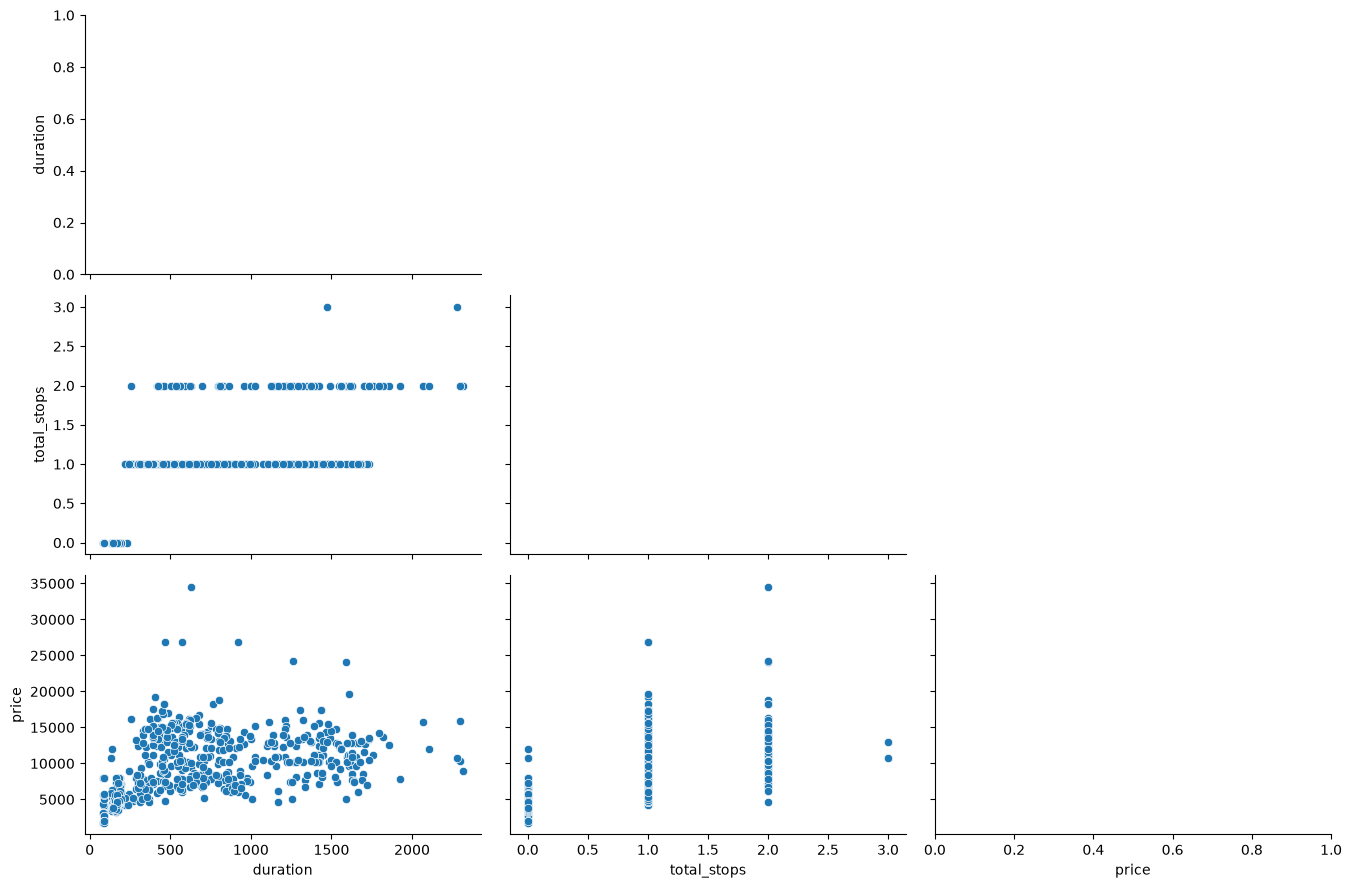

In [18]:
eda_helper_functions.pair_plots(train)

## 7. Correlation Analysis

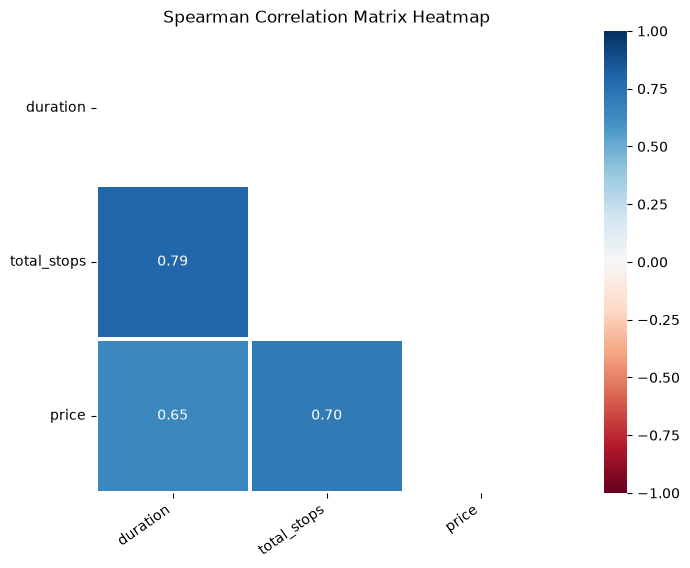

In [19]:
eda_helper_functions.correlation_heatmap(train)

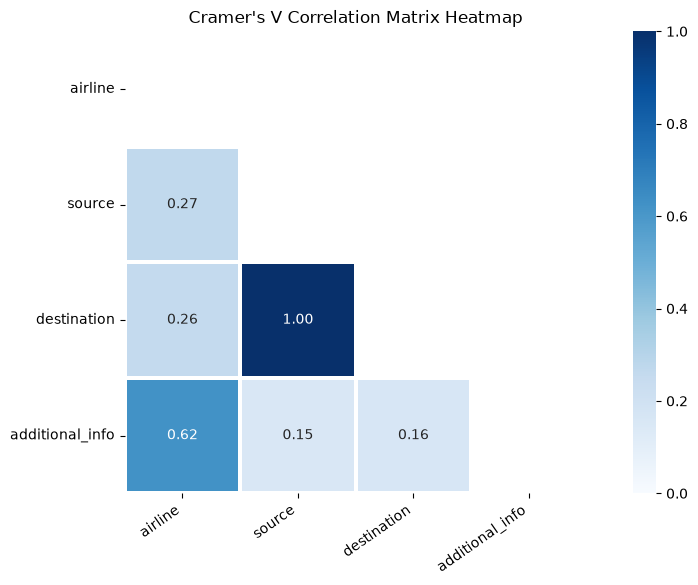

In [20]:
eda_helper_functions.cramersV_heatmap(train)

## 8. Detailed Analysis

In [22]:
train.columns

Index(['airline', 'date_of_journey', 'source', 'destination', 'dep_time',
       'arrival_time', 'duration', 'total_stops', 'additional_info', 'price'],
      dtype='str')

### 8.1 airline

In [23]:
train.airline

0                 Indigo
1                Vistara
2            Jet Airways
3            Jet Airways
4            Jet Airways
             ...        
635            Air India
636               Indigo
637    Multiple Carriers
638               Indigo
639             Spicejet
Name: airline, Length: 640, dtype: str

In [24]:
eda_helper_functions.cat_summary(train, "airline")

0                 Indigo
1                Vistara
2            Jet Airways
3            Jet Airways
4            Jet Airways
             ...        
635            Air India
636               Indigo
637    Multiple Carriers
638               Indigo
639             Spicejet
Name: airline, Length: 640, dtype: str

Data Type      : str
Cardinality    : 8 categories
Missing Data   : 0 rows (0.00 %)
Available Data : 640 / 640 rows


,
count,640
unique,8
top,Jet Airways
freq,243


,count,percentage
category,,
Jet Airways,243,0.379688
Indigo,122,0.190625
Air India,93,0.145313
Multiple Carriers,88,0.137500
Spicejet,49,0.076563
Vistara,24,0.037500
Air Asia,11,0.017188
Goair,10,0.015625


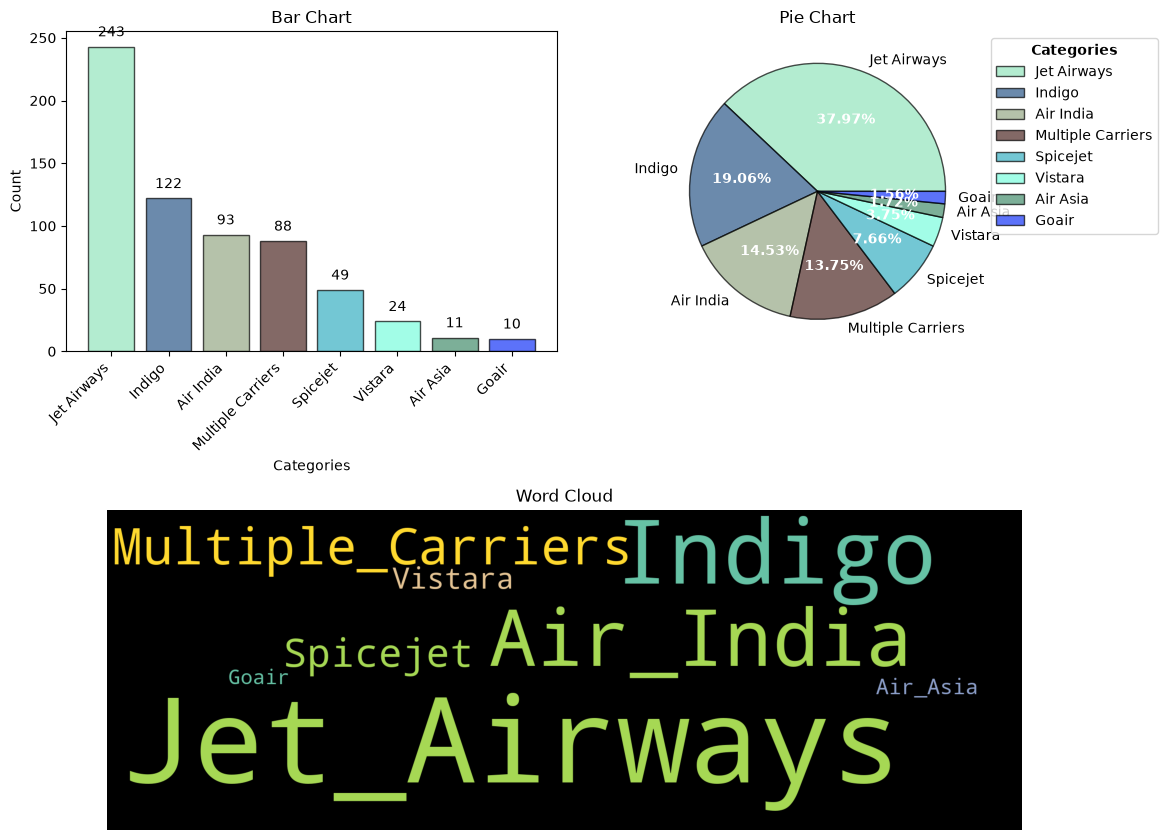

In [25]:
eda_helper_functions.cat_univar_plots(train, "airline")

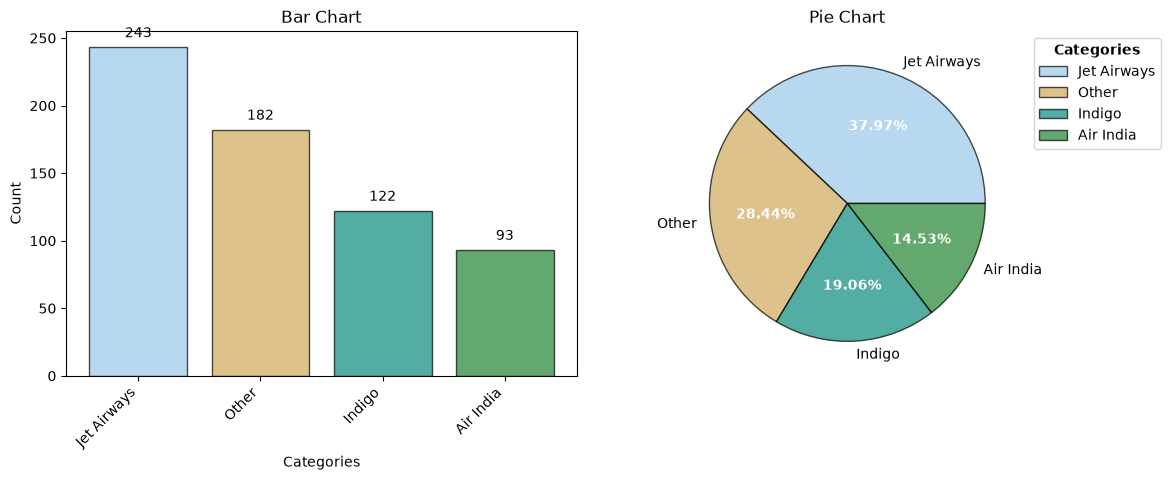

In [26]:
eda_helper_functions.cat_univar_plots(train, "airline", show_wordcloud=False, k=3)

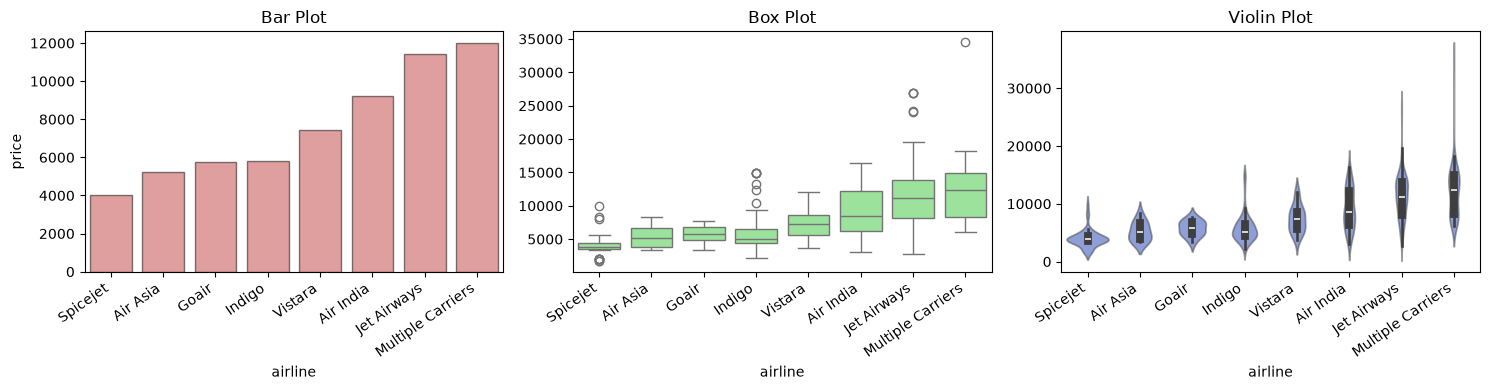

In [27]:
eda_helper_functions.num_cat_bivar_plots(
	data=train,
	num_var="price",
	cat_var="airline"
)

In [28]:
eda_helper_functions.num_cat_hyp_testing(train, "price", "airline")

- Significance Level   : 5.0%
- Null Hypothesis      : The groups have similar population mean
- Alternate Hypothesis : The groups don't have similar population mean
- Test Statistic       : 60.784353141316465
- p-value              : 1.2749592107781296e-66
- Since p-value is less than 0.05, we Reject the Null Hypothesis at 5.0% significance level
- CONCLUSION: The variables price and airline are associated to each other


- Significance Level   : 5.0%
- Null Hypothesis      : The groups have similar population median
- Alternate Hypothesis : The groups don't have similar population median
- Test Statistic       : 300.67273130556225
- p-value              : 4.345739014778357e-61
- Since p-value is less than 0.05, we Reject the Null Hypothesis at 5.0% significance level
- CONCLUSION: The variables price and airline are associated to each other


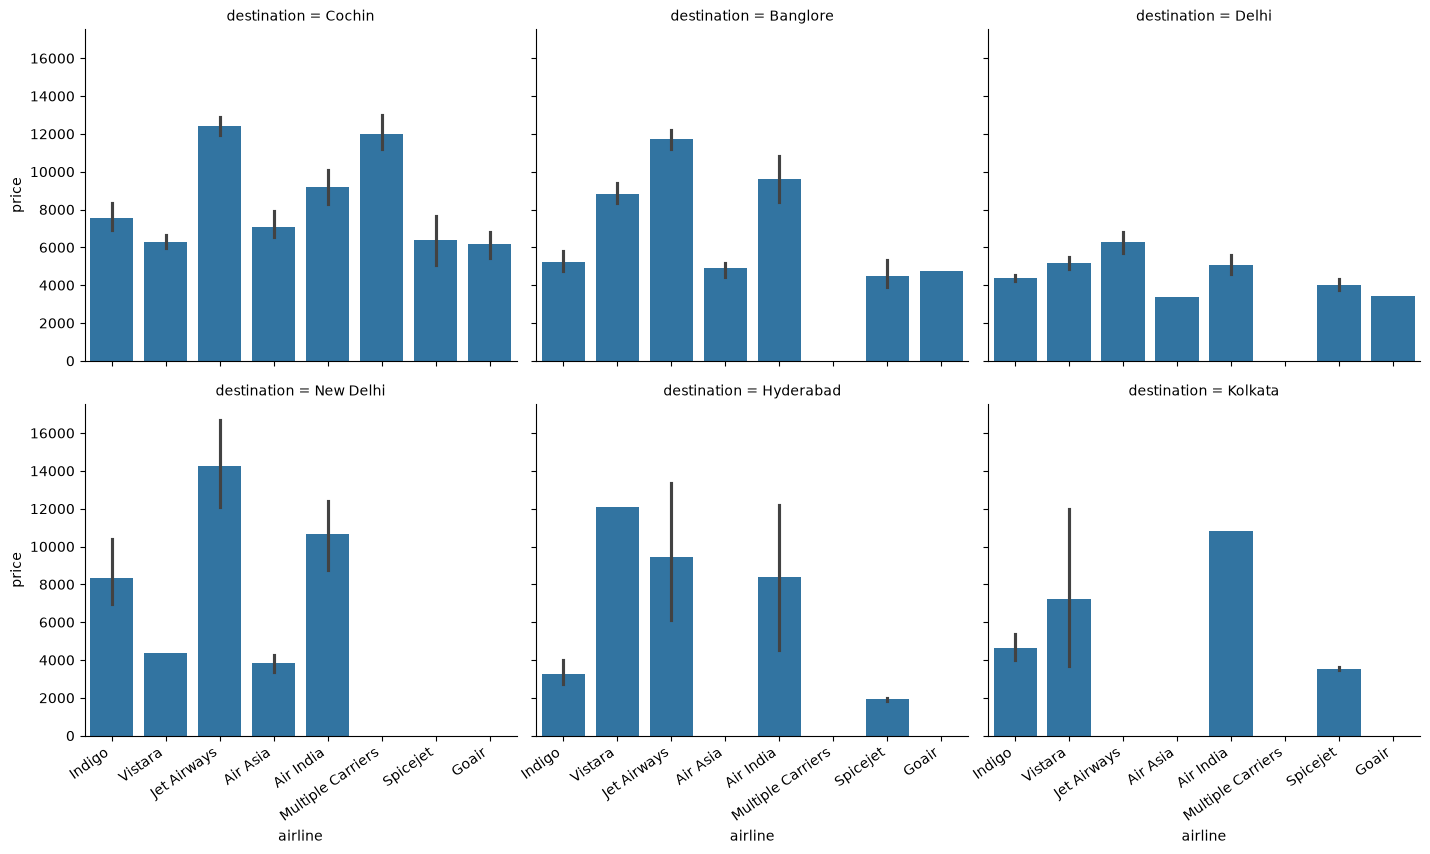

In [30]:
airline_grid = sns.FacetGrid(
	data=train,
	col="destination",
	col_wrap=3,
	height=4,
	aspect=1.2,
	sharey=True
)

airline_grid.map(sns.barplot, "airline", "price", order=train.airline.unique())

for ax in airline_grid.axes[3:]:
	eda_helper_functions.rotate_xlabels(ax)

### 8.2 date_of_journey

In [31]:
train.date_of_journey

0     2019-04-27
1     2019-01-04
2     2019-05-27
3     2019-06-24
4     2019-05-18
         ...    
635   2019-01-06
636   2019-04-27
637   2019-06-06
638   2019-12-04
639   2019-09-06
Name: date_of_journey, Length: 640, dtype: datetime64[us]

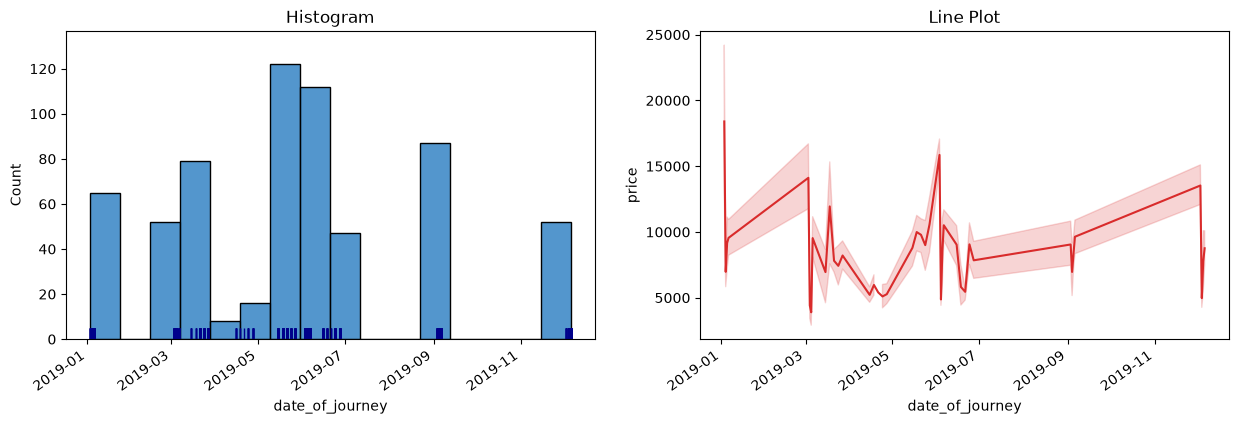

In [32]:
eda_helper_functions.dt_univar_plots(
	data=train,
	var="date_of_journey",
	target="price"
)

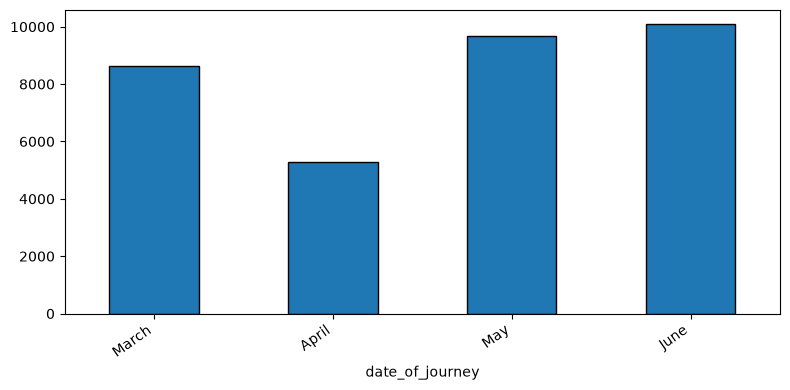

In [36]:
monthly_price = (
    train
    .groupby(pd.Grouper(key="date_of_journey", freq="ME"))
    .price.mean()
)

# Keep only March, April, May, and June
monthly_price = monthly_price[monthly_price.index.month.isin([3, 4, 5, 6])]

# Plot with month names
ax = monthly_price.set_axis(
    monthly_price.index.strftime("%B")
).plot(
    kind="bar",
    figsize=(8, 4),
    edgecolor="black"
)

eda_helper_functions.rotate_xlabels(ax)
plt.tight_layout()
plt.show()


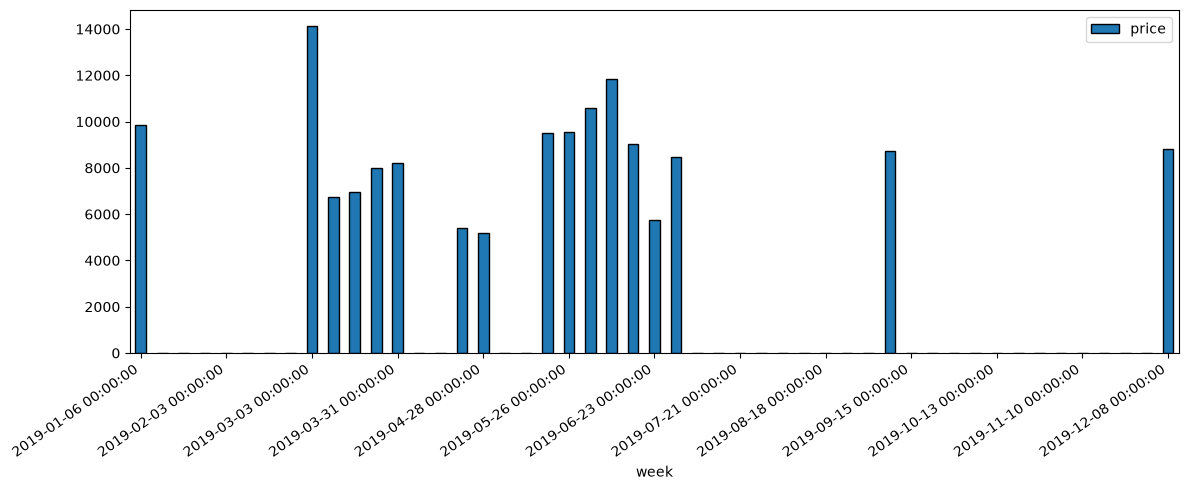

In [41]:


(
    train
    .groupby(pd.Grouper(key="date_of_journey", freq="W"))
    .price.mean()
    .to_frame()
    .rename_axis(index="week")
    .plot(
        kind="bar",
        figsize=(12, 5),
        edgecolor="black"
    )
)

ax = plt.gca()

# Get all tick positions and labels
ticks = ax.get_xticks()
labels = ax.get_xticklabels()

# Display every fourth label
step = 4
ax.set_xticks(ticks[::step])
ax.set_xticklabels(
    [label.get_text() for label in labels[::step]],
    rotation=35,
    ha="right"
)

plt.tight_layout()
plt.show()


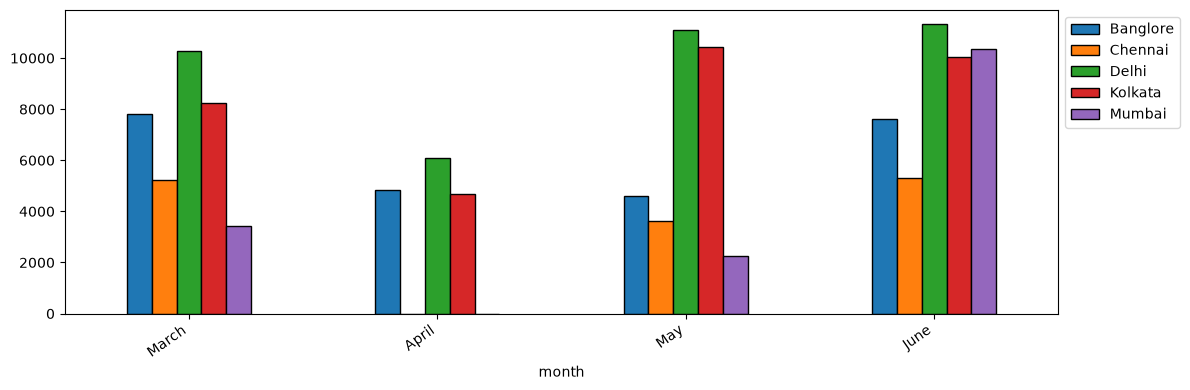

In [43]:

(
    train
    .loc[train["date_of_journey"].dt.month.isin([3, 4, 5, 6])]
    .groupby([
        pd.Grouper(key="date_of_journey", freq="ME"),
        "source"
    ])
    .price.mean()
    .unstack(fill_value=0)
    .rename_axis(index="month")
    .rename(index=lambda date: date.strftime("%B"))
    .plot(
        kind="bar",
        figsize=(12, 4),
        edgecolor="black"
    )
)

ax = plt.gca()

ax.legend(
    loc="upper left",
    bbox_to_anchor=(1, 1)
)

eda_helper_functions.rotate_xlabels(ax)
plt.tight_layout()
plt.show()


### 8.3 dep_time

In [44]:
train.dep_time

0     2026-10-11 16:00:00
1     2026-10-11 07:10:00
2     2026-10-11 14:00:00
3     2026-10-11 20:55:00
4     2026-10-11 14:00:00
              ...        
635   2026-10-11 14:25:00
636   2026-10-11 04:00:00
637   2026-10-11 11:25:00
638   2026-10-11 10:10:00
639   2026-10-11 09:00:00
Name: dep_time, Length: 640, dtype: datetime64[us]

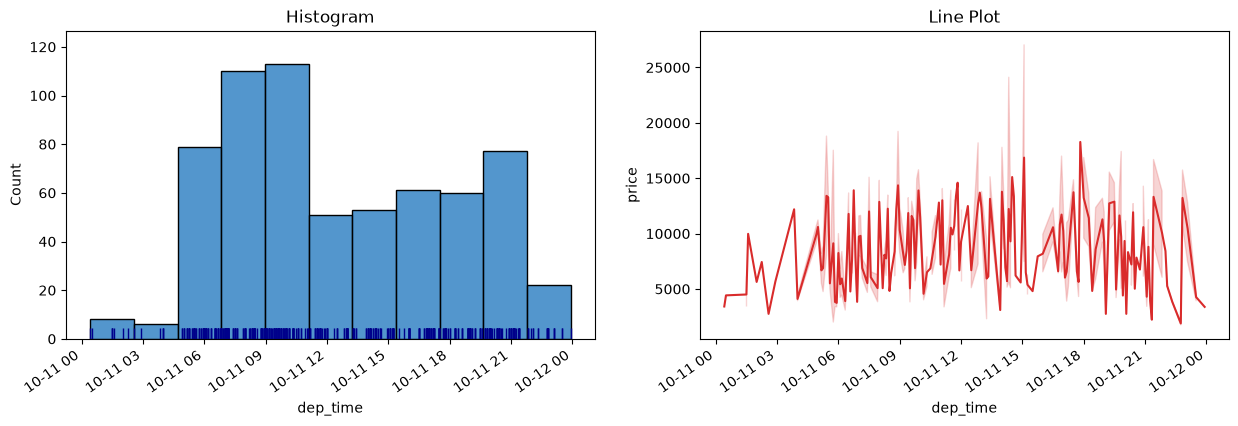

In [45]:
eda_helper_functions.dt_univar_plots(train, "dep_time", "price")

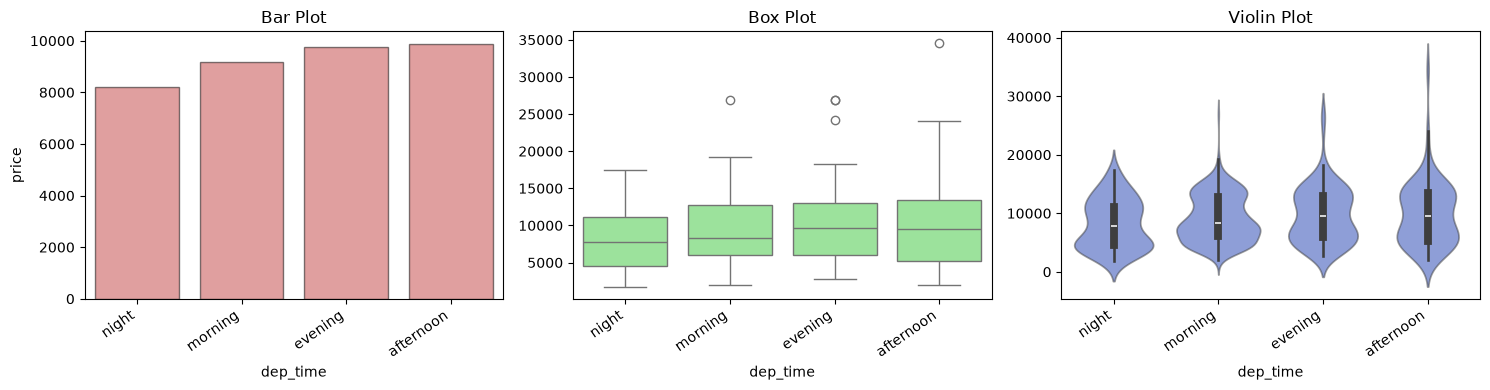

In [46]:
(
	train
	.assign(dep_time=lambda df_: (
		np.select([df_.dep_time.dt.hour.between(4, 12, inclusive="left"),
				   df_.dep_time.dt.hour.between(12, 16, inclusive="left"),
				   df_.dep_time.dt.hour.between(16, 20, inclusive="left")],
				  ["morning", "afternoon", "evening"],
				  default="night")
	))
	.pipe(eda_helper_functions.num_cat_bivar_plots, "price", "dep_time")
)

### 8.4 duration

In [47]:
train.duration

0       300
1       975
2       300
3      1325
4       300
       ... 
635    1730
636     170
637     455
638     170
639     145
Name: duration, Length: 640, dtype: int64

In [48]:
eda_helper_functions.num_summary(train, "duration")

0       300
1       975
2       300
3      1325
4       300
       ... 
635    1730
636     170
637     455
638     170
639     145
Name: duration, Length: 640, dtype: int64

Data Type      : int64
Missing Data   : 0 rows (0.00 %)
Available Data : 640 / 640 rows


,value
percentile,
0,80.00
5,90.00
10,150.00
25,178.75
50,522.50
75,943.75
90,1485.00
95,1630.00
99,2013.45


,value
mean,660.054688
trimmed mean (5%),627.118056
trimmed mean (10%),598.730469
median,522.500000


,value
var,267350.583859
std,517.059555
IQR,765.000000
mad,347.500000
coef_variance,0.783359


,value
skewness,0.882583
kurtosis,-0.171781


Significance Level   : 0.05
Null Hypothesis      : The data is normally distributed
Alternate Hypothesis : The data is not normally distributed
p-value              : 2.7202664299485685e-21
Test Statistic       : 0.8861942060800058
- Since p-value is less than alpha (0.05), we Reject the Null Hypothesis at 5.0% significance level
- CONCLUSION: We conclude that the data sample is not normally distributed


Significance Level   : 0.05
Null Hypothesis      : The data is normally distributed
Alternate Hypothesis : The data is not normally distributed
Critical Value       : 0.751
Test Statistic       : 24.285164275885336
- Since the Test-statistic is greater than Critical Value, we Reject the Null Hypothesis at 5.0% significance level
- CONCLUSION: We conclude that the data sample is not normally distributed


In [49]:
train.duration.quantile([0.25, 0.5, 0.75])

0.25    178.75
0.50    522.50
0.75    943.75
Name: duration, dtype: float64

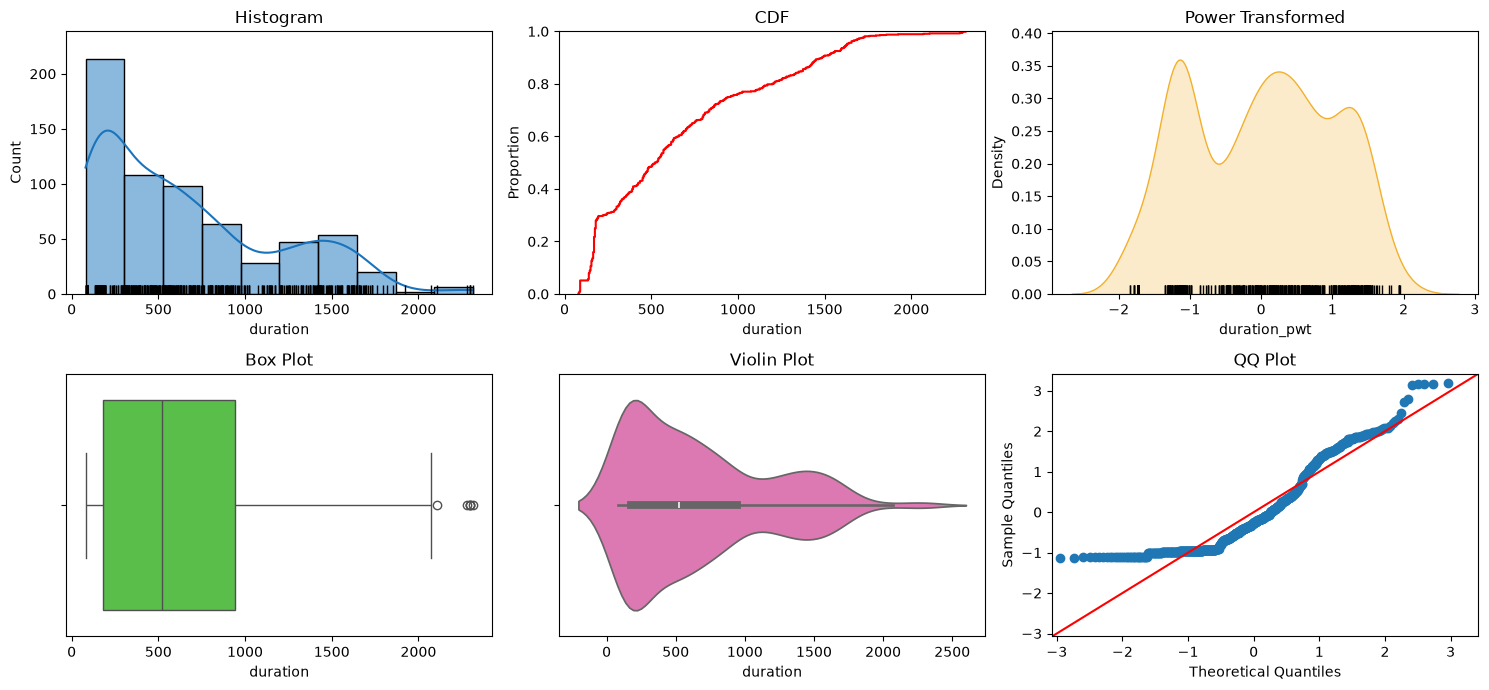

In [50]:
eda_helper_functions.num_univar_plots(train, "duration")

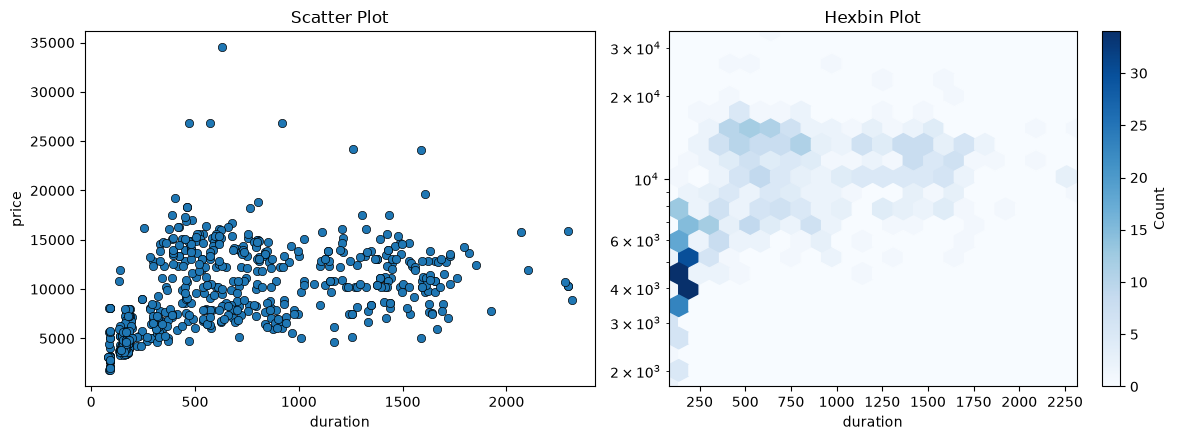

In [51]:
eda_helper_functions.num_bivar_plots(
	train,
	"duration",
	"price",
	hexbin_kwargs=dict(
		yscale="log",
		gridsize=20,
		cmap="Blues"
	)
)

In [52]:
eda_helper_functions.num_num_hyp_testing(train, "price", "duration")

- Significance Level   : 5.0%
- Null Hypothesis      : The samples are uncorrelated
- Alternate Hypothesis : The samples are correlated
- Test Statistic       : 0.47715076301940096
- p-value              : 1.0642578282037051e-37
- Since p-value is less than 0.05, we Reject the Null Hypothesis at 5.0% significance level
- CONCLUSION: The variables price and duration are correlated


- Significance Level   : 5.0%
- Null Hypothesis      : The samples are uncorrelated
- Alternate Hypothesis : The samples are correlated
- Test Statistic       : 0.6458050070966445
- p-value              : 8.34351269363902e-77
- Since p-value is less than 0.05, we Reject the Null Hypothesis at 5.0% significance level
- CONCLUSION: The variables price and duration are correlated


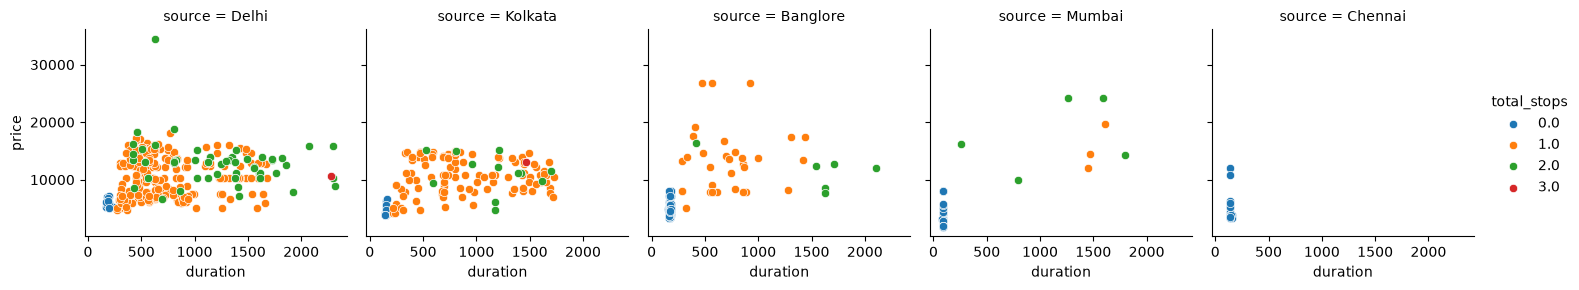

In [54]:
duration_grid = sns.FacetGrid(
	data=train,
	col="source",
	hue="total_stops",
	sharey=True
)

duration_grid.map(sns.scatterplot, "duration", "price")

duration_grid.add_legend()

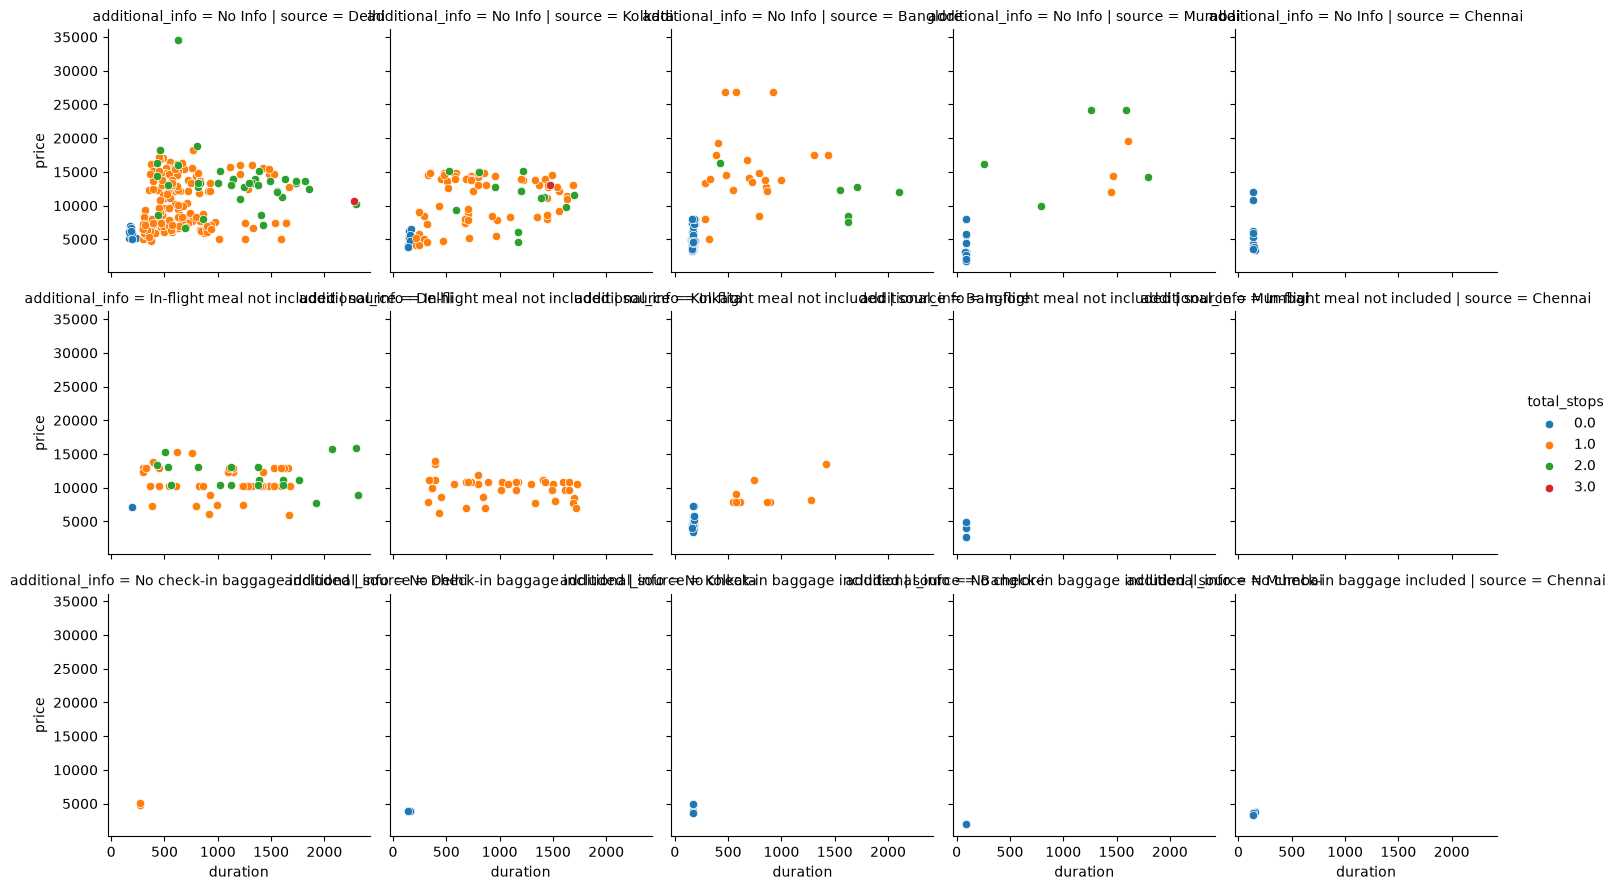

In [55]:
duration_grid = sns.FacetGrid(
	data=train,
	col="source",
	row="additional_info",
	hue="total_stops",
	sharey=True
)

duration_grid.map(sns.scatterplot, "duration", "price")

duration_grid.add_legend()

In [56]:
eda_helper_functions.get_iqr_outliers(train, "duration")

Lower Limit : -968.75
Upper Limit : 2091.25


,airline,date_of_journey,source,destination,dep_time,arrival_time,duration,total_stops,additional_info,price
525,Air India,2019-03-03,Banglore,New Delhi,2026-10-11 11:05:00,2026-10-11 22:10:00,2105,2.0,No Info,11948
396,Air India,2019-06-15,Delhi,Cochin,2026-10-11 05:15:00,2026-10-11 19:15:00,2280,3.0,No Info,10703
22,Air India,2019-06-03,Delhi,Cochin,2026-10-11 05:00:00,2026-10-11 19:15:00,2295,2.0,No Info,10283
188,Jet Airways,2019-06-03,Delhi,Cochin,2026-10-11 05:30:00,2026-10-11 19:45:00,2295,2.0,In-flight meal not included,15864
218,Air India,2019-03-03,Delhi,Cochin,2026-10-11 05:00:00,2026-10-11 19:15:00,2295,2.0,No Info,10283
182,Jet Airways,2019-03-27,Delhi,Cochin,2026-10-11 05:10:00,2026-10-11 19:45:00,2315,2.0,In-flight meal not included,8938


### 8.5 additional_info

In [57]:
eda_helper_functions.cat_summary(train, "additional_info")

0                           No Info
1                           No Info
2       In-flight meal not included
3       In-flight meal not included
4       In-flight meal not included
                   ...             
635                         No Info
636                         No Info
637                         No Info
638                         No Info
639    No check-in baggage included
Name: additional_info, Length: 640, dtype: str

Data Type      : str
Cardinality    : 3 categories
Missing Data   : 0 rows (0.00 %)
Available Data : 640 / 640 rows


,
count,640
unique,3
top,No Info
freq,483


,count,percentage
category,,
No Info,483,0.754687
In-flight meal not included,135,0.210938
No check-in baggage included,22,0.034375


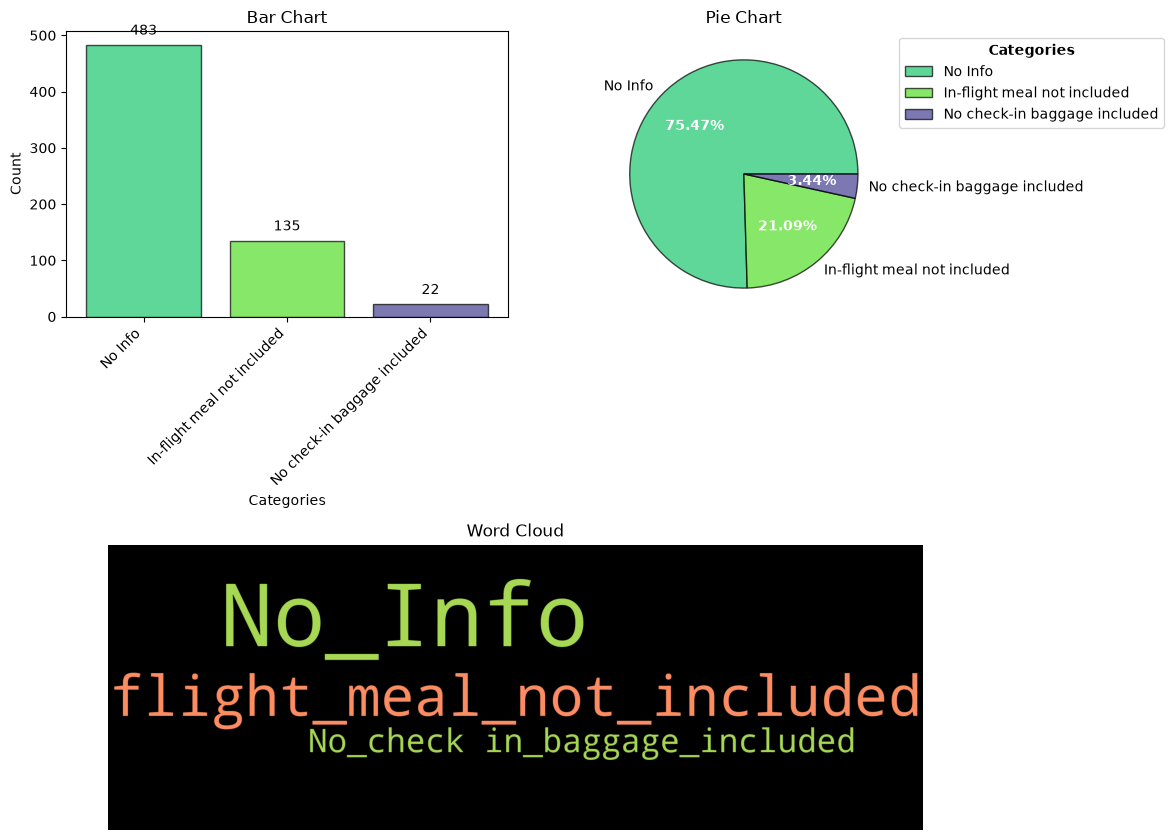

In [58]:
eda_helper_functions.cat_univar_plots(train, "additional_info")

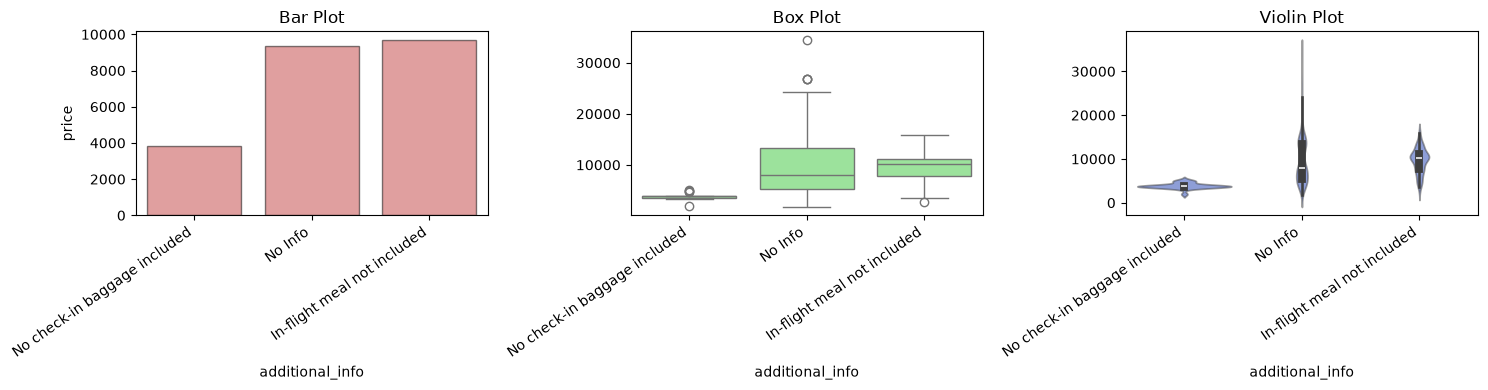

In [59]:
eda_helper_functions.num_cat_bivar_plots(train, "price", "additional_info")

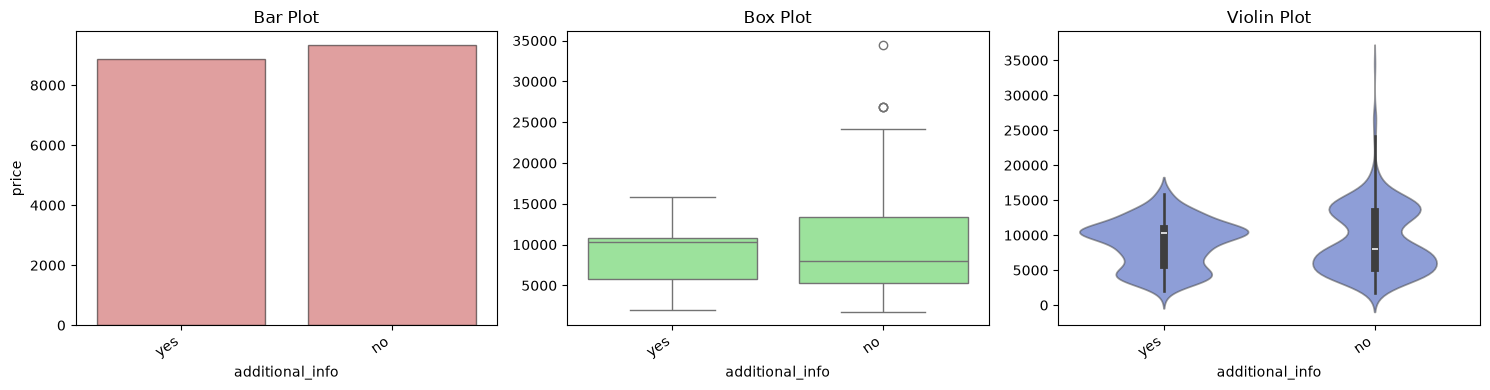

In [60]:
# convertion additional_info into a binary feature for analysis

(
	train
	.assign(additional_info=(
		train
		.additional_info
		.pipe(lambda ser: np.where(ser.eq("No Info"), "no", "yes"))
	))
	.pipe(eda_helper_functions.num_cat_bivar_plots, "price", "additional_info")
)

- `additional_info` has severely rare categories
- Converted it into a binary feature for further analysis

## 9. Automated EDA

In [45]:
# from ydata_profiling import ProfileReport

In [46]:
# report = ProfileReport(train)

In [47]:
# report.to_file(output_file="output.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]